# 02 · Trade integrity and the trade–book acceptance tests (Stage 0.4–0.6)
**Microstructure Alpha · Binance USD-M ETHUSDT perpetual · 7–14 Sep 2026**

Notebook 01 rebuilt the book. This notebook checks it against an **independent data source, the trades**. It is the main check for the 169 hours that had no snapshot to audit against.

| Section | What it does |
|---|---|
| 1 | Loads each day's trades **exactly** (integer ticks and lots) and checks IDs, time order, grids, and `quote_qty = price × qty` |
| 2 | **Test 2**: every buy must print at the replayed **ask** and every sell at the **bid**, within one update batch |
| 3 | Sweeps: fills beyond the touch must follow a touch fill in the same batch and walk the book in price order. **Test 3**: traded volume at the touch vs the queue resting there |
| 4 | Missing trade IDs (~0.5%): do they take visible liquidity? (exploratory) |
| 5 | Quality windows: periods where the book is invalid (after a `pu` break, until resync) or the feed is delayed more than `LAT_BAD_MS`. Later notebooks exclude these |
| 6 | Sanity plots across all 8 days |
| 7 | Daily integrity report and the **final Stage 0 gate** |

### How a trade is matched to the book
Trade time and the book's `transaction_time` both come from the matching engine (ms). A trade at time *t* belongs to the **first batch with T ≥ t**. Its **pre-state** is the book after the previous batch, and its **post-state** is the book after that batch. Trades are classified as:

| Class | Meaning | Counts as |
|---|---|---|
| `at_touch` | Buy at the pre-batch best ask / sell at the best bid | explained |
| `deeper_top10` | Beyond the touch, at a level that was in the pre-batch top 10 (a sweep) | explained |
| `beyond_top10` | Beyond the 10th level, so it can't be checked against the saved top 10. Checked through sweep order instead (section 3) | explained (sweep-verified) |
| `one_batch_slack` | Matches the touch one batch earlier, or a level in the post-batch book | explained |
| `inside_spread`, `wrong_side`, `other` | Not reconcilable with batch-level data. Usually orders added and taken inside one ~27 ms batch during fast moves | **unexplained** |

Trades in invalid book periods, or at the first batch after a mid-hour resync, are counted separately as *unusable* and left out of the tests.

**Runtime:** about 10 minutes. **Inputs:** the book files and reports from notebook 01, plus your trade files.

In [1]:
# ===================== CONFIG — same paths as notebook 01 =====================
from pathlib import Path
ROOT_DIR   = Path(r"C:\microalpha_proj\Micro Alpha")     # folder with the day folders (L2 + trades)
OUT_DIR    = Path(r"C:\microalpha_proj\microoutput")     # notebook 01 output folder
DATES      = [f"2026-09-{d:02d}" for d in range(7, 15)]
SYMBOL     = "ETHUSDT"
K_LEVELS   = 10
LAT_BAD_MS = 1000     # feed latency above this marks a 'latency' quality window
STRICT     = True
# thresholds for the gate (written before looking at the full results)
MAX_UNEXPLAINED_TRADES = 0.005   # ≤ 0.5% of usable trades per day
MAX_UNEXPLAINED_VOLUME = 0.010   # ≤ 1.0% of usable volume per day
MIN_SWEEP_PRECEDED     = 0.95    # deeper fills preceded by a touch fill in the same batch & side
MIN_SWEEP_MONOTONE     = 0.99    # batch-sides whose fills walk the book in price order
MIN_USABLE_SHARE       = 0.95    # trades that fall in valid book periods
# ===============================================================================

In [2]:
import sys, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd()))
import ma_lib
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)
REP, BOOK, TRD = OUT_DIR / 'reports', OUT_DIR / 'book', OUT_DIR / 'trades'
TRD.mkdir(exist_ok=True)
sync = pd.read_csv(REP / '01_sync_log.csv')
xchk = pd.read_csv(REP / '01_engine_crosscheck.csv')
inv = ma_lib.inventory(ROOT_DIR, SYMBOL)
tfiles = ma_lib.pick_trade_files(inv, DATES)
book_files = {(d, h): BOOK / d / f'book_{d}_{h:02d}.parquet' for d in DATES for h in range(24)}
missing_books = [k for k, p in book_files.items() if not p.exists()]
print('trade files:'); [print('  ', d, Path(p).name) for d, p in tfiles.items()]
print('book files missing:', len(missing_books), '| trade days missing:', sorted(set(DATES) - set(tfiles)))
if STRICT and (missing_books or set(DATES) - set(tfiles)): raise RuntimeError('run notebook 01 first / add the missing trade files')

trade files:
   2026-09-07 ETHUSDT-trades-2026-09-07.csv
   2026-09-08 ETHUSDT-trades-2026-09-08.csv
   2026-09-09 ETHUSDT-trades-2026-09-09.csv
   2026-09-10 ETHUSDT-trades-2026-09-10.csv
   2026-09-11 ETHUSDT-trades-2026-09-11.csv
   2026-09-12 ETHUSDT-trades-2026-09-12.csv
   2026-09-13 ETHUSDT-trades-2026-09-13.csv
   2026-09-14 ETHUSDT-trades-2026-09-14.csv
book files missing: 0 | trade days missing: []


## 1–5 · Main pass: one day at a time, one hour at a time
For each day: load and check the trades, join every hour to its book, write the annotated trades to `OUT_DIR/trades/trades_<date>.parquet`, and collect quality windows and one-second samples for the plots. Trades in the last ~100 ms of a day (after that day's final batch) are joined to the next day's first batch.

In [3]:
t_start = time.time()
integ, hourly, unexpl, windows, persec, tmin = [], [], [], [], [], []
prev_row, prev_day = None, None

def save_day(pd_):
    out = pd_['tr'].assign(u_post=pd_['u_post'], cls=pd_['cls'])
    out.to_parquet(TRD / f"trades_{pd_['date']}.parquet", compression='zstd', index=False)

def record(date, hour, ann, st, unx, day):
    day['u_post'][ann.idx.to_numpy()] = ann.u_post.to_numpy(); day['cls'][ann.idx.to_numpy()] = ann.cls.to_numpy()
    hourly.append(dict(date=date, hour=hour, **st))
    if len(unx): unexpl.append(unx.assign(date=date, hour=hour))

for date in DATES:
    t0 = time.time()
    tr, info = ma_lib.load_trades_day(tfiles[date]); integ.append(dict(date=date, **info))
    day = dict(date=date, tr=tr, u_post=np.full(len(tr), -1, np.int64), cls=np.full(len(tr), -1, np.int8))
    tmin.append(tr.assign(m=tr.time // 60000).groupby('m').agg(trades=('id', 'size'), vol=('qty', 'sum')).reset_index())
    for hour in range(24):
        p = book_files[(date, hour)]
        if not p.exists(): prev_row = None; continue
        book = pd.read_parquet(p)
        if hour == 0 and prev_day is not None:          # previous day's last ~100 ms of trades
            ann, st, unx = ma_lib.join_hour(book, prev_row, prev_day['tr'], K_LEVELS)
            record(prev_day['date'], 24, ann, st, unx, prev_day); save_day(prev_day); prev_day = None
        ann, st, unx = ma_lib.join_hour(book, prev_row, tr, K_LEVELS)
        record(date, hour, ann, st, unx, day)
        for w in ma_lib.quality_windows(book, LAT_BAD_MS): windows.append(dict(date=date, hour=hour, **w))
        seg = book.seg.to_numpy(); rs = np.nonzero((seg[1:] > 0) & (seg[1:] != seg[:-1]))[0] + 1
        for r_ in rs:                                    # unknown book between the old segment and the resync snapshot
            windows.append(dict(date=date, hour=hour, reason='resync_gap', start_T=int(book['T'].iloc[r_ - 1]),
                                end_T=int(book['T'].iloc[r_]), batches=1, max_latency_ms=np.nan))
        ps = ma_lib.per_second(book); persec.append(ps)
        prev_row = book.iloc[[-1]]
        del book
    prev_day = day
    h = pd.DataFrame([x for x in hourly if x['date'] == date])
    print(f"{date}: {info['rows']:>9,} trades | missing IDs {info['missing_ids']:>6,} | "
          f"usable {h.usable.sum()/max(1,h.trades.sum()):.2%} | unexplained "
          f"{(h.n_inside_spread + h.n_wrong_side + h.n_other).sum()/max(1,h.usable.sum()):.3%} | {time.time()-t0:.0f}s")
if prev_day is not None: save_day(prev_day)
integ = pd.DataFrame(integ); hourly = pd.DataFrame(hourly); windows = pd.DataFrame(windows)
persec = pd.concat(persec, ignore_index=True); tmin = pd.concat(tmin, ignore_index=True)
unexpl = pd.concat(unexpl, ignore_index=True) if unexpl else pd.DataFrame()
integ.to_csv(REP / '02_trades_integrity.csv', index=False); hourly.to_csv(REP / '02_join_by_hour.csv', index=False)
windows.to_csv(REP / '02_quality_windows.csv', index=False)
if len(unexpl): unexpl.head(5000).to_csv(REP / '02_unexplained_examples.csv', index=False)
print(f'done in {(time.time()-t_start)/60:.1f} min')

2026-09-07: 3,599,862 trades | missing IDs 17,706 | usable 99.74% | unexplained 0.571% | 20s
2026-09-08: 4,254,574 trades | missing IDs 18,156 | usable 96.91% | unexplained 0.570% | 21s
2026-09-09: 4,687,541 trades | missing IDs 18,673 | usable 99.01% | unexplained 0.600% | 24s
2026-09-10: 4,552,897 trades | missing IDs 18,164 | usable 97.00% | unexplained 0.645% | 22s
2026-09-11: 7,910,411 trades | missing IDs 23,965 | usable 99.80% | unexplained 1.960% | 34s
2026-09-12: 1,713,727 trades | missing IDs 10,104 | usable 96.65% | unexplained 0.486% | 13s
2026-09-13: 2,734,970 trades | missing IDs 10,202 | usable 97.10% | unexplained 0.714% | 15s
2026-09-14: 5,801,859 trades | missing IDs 22,483 | usable 98.30% | unexplained 0.788% | 21s
done in 2.9 min


## 1 · Trade integrity by day

In [4]:
cols = ['date','rows','missing_ids','missing_id_share','id_gaps','max_id_gap','dup_or_backward_ids','time_decreases',
        'offgrid_px','offgrid_qty','quote_mismatch','quote_sci_rows','bad_side_values','zero_qty','buy_share','max_trade_eth','max_trade_time']
display(integ[cols])

,date,rows,missing_ids,missing_id_share,id_gaps,max_id_gap,dup_or_backward_ids,time_decreases,offgrid_px,offgrid_qty,quote_mismatch,quote_sci_rows,bad_side_values,zero_qty,buy_share,max_trade_eth,max_trade_time
0,2026-09-07,3599862,17706,0.004894,17152,4,0,0,0,0,0,1,0,0,0.497562,5925.078,2026-09-07 18:50:07.600
1,2026-09-08,4254574,18156,0.004249,17655,3,0,0,0,0,0,2,0,0,0.503891,6483.678,2026-09-08 02:22:46.379
2,2026-09-09,4687541,18673,0.003968,18202,4,0,0,0,0,0,0,0,0,0.498250,1452.300,2026-09-09 08:51:25.031
3,2026-09-10,4552897,18164,0.003974,17671,3,0,0,0,0,0,0,0,0,0.489189,3445.820,2026-09-10 15:58:35.623
4,2026-09-11,7910411,23965,0.003020,22968,9,0,0,0,0,0,2,0,0,0.501102,4893.739,2026-09-11 13:46:08.359
5,2026-09-12,1713727,10104,0.005861,9820,3,0,0,0,0,0,0,0,0,0.526772,2682.459,2026-09-12 03:22:59.727
6,2026-09-13,2734970,10202,0.003716,9964,4,0,0,0,0,0,0,0,0,0.500129,1728.918,2026-09-13 06:55:00.256
7,2026-09-14,5801859,22483,0.003860,21949,3,0,0,0,0,0,2,0,0,0.501520,5164.083,2026-09-14 14:58:26.649


## 2 · Test 2: trade price vs replayed book
Shares are of **usable** trades (valid book on both sides of the batch). *Unexplained* = `inside_spread` + `wrong_side` + `other`.

In [5]:
names = list(ma_lib.CLS.values())
day = hourly.groupby('date').sum(numeric_only=True)
tab = pd.DataFrame({'trades': day.trades, 'usable_share': day.usable / day.trades})
for n in names: tab[n] = day[f'n_{n}'] / day.usable
tab['unexplained'] = tab[['inside_spread', 'wrong_side', 'other']].sum(axis=1)
tab['unexplained_vol'] = (day.v_inside_spread + day.v_wrong_side + day.v_other) / day.vol_usable
tot = hourly.sum(numeric_only=True)
tab.loc['ALL'] = [tot.trades, tot.usable / tot.trades] + [tot[f'n_{n}'] / tot.usable for n in names] + \
                 [(tot.n_inside_spread + tot.n_wrong_side + tot.n_other) / tot.usable,
                  (tot.v_inside_spread + tot.v_wrong_side + tot.v_other) / tot.vol_usable]
display(tab.style.format({c: '{:.3%}' for c in tab.columns if c != 'trades'} | {'trades': '{:,.0f}'}))
tab.to_csv(REP / '02_join_by_day.csv')

,trades,usable_share,at_touch,deeper_top10,beyond_top10,one_batch_slack,inside_spread,wrong_side,other,unexplained,unexplained_vol
date,,,,,,,,,,,
2026-09-07,"3,599,862",99.737%,43.861%,27.420%,27.417%,0.731%,0.085%,0.394%,0.092%,0.571%,1.697%
2026-09-08,"4,254,574",96.907%,42.537%,27.961%,28.164%,0.769%,0.110%,0.358%,0.102%,0.570%,1.564%
2026-09-09,"4,687,541",99.008%,42.681%,28.153%,27.840%,0.727%,0.103%,0.401%,0.095%,0.600%,1.858%
2026-09-10,"4,552,897",97.000%,45.841%,28.031%,24.613%,0.871%,0.101%,0.399%,0.145%,0.645%,1.997%
2026-09-11,"7,910,411",99.797%,38.191%,27.180%,31.037%,1.632%,0.241%,1.282%,0.437%,1.960%,4.215%
2026-09-12,"1,713,727",96.650%,52.907%,22.058%,23.839%,0.711%,0.115%,0.284%,0.087%,0.486%,1.432%
2026-09-13,"2,734,970",97.102%,48.808%,23.368%,26.224%,0.887%,0.182%,0.364%,0.168%,0.714%,1.927%
2026-09-14,"5,801,646",98.297%,42.018%,27.646%,28.616%,0.931%,0.106%,0.520%,0.162%,0.788%,2.559%
ALL,"35,255,628",98.367%,43.015%,27.076%,27.964%,1.002%,0.140%,0.606%,0.196%,0.943%,2.475%


In [6]:
# where do unexplained trades come from? concentrated in a few fast-market batches, or spread out?
if len(unexpl):
    unexpl['minute'] = pd.to_datetime(unexpl.time, unit='ms').dt.floor('min')
    by_min = unexpl.groupby('minute').size().sort_values(ascending=False)
    print(f'unexplained trades: {len(unexpl):,} in {by_min.size:,} distinct minutes; top 10 minutes hold '
          f'{by_min.head(10).sum()/len(unexpl):.1%}')
    display(by_min.head(10).rename('unexplained trades').to_frame())
    print('by class:', unexpl.cls.map(ma_lib.CLS).value_counts().to_dict())

unexplained trades: 326,921 in 6,439 distinct minutes; top 10 minutes hold 20.9%


,unexplained trades
minute,
2026-09-11 13:49:00,12084
2026-09-11 13:59:00,9424
2026-09-11 14:03:00,8201
2026-09-11 14:02:00,7873
2026-09-11 13:52:00,6784
2026-09-11 12:37:00,5574
2026-09-11 13:58:00,5378
2026-09-11 13:50:00,5304
2026-09-11 12:30:00,4522


by class: {'wrong_side': 210250, 'other': 68028, 'inside_spread': 48643}


## 3 · Sweeps and Test 3 (queue at the touch)
- **preceded:** fills beyond the touch (`deeper_top10` + `beyond_top10`) that come after a touch fill in the same batch and side. This is how the `beyond_top10` fills are checked.
- **monotone:** batch-sides whose fills, in trade-ID order, never move back toward the touch.
- **Test 3:** for each batch-side with trading at the pre-batch touch, compare volume **V** with the resting queue **q_pre**. *V ≤ q_pre* means the fills fit in the queue that was visible. When *V > q_pre − q_post*, the level must also have received **new orders within the same batch**, so add and cancel volumes are only lower bounds there. Without order-level data this test can't strictly fail; it measures how often that happens.

In [7]:
sw = hourly.groupby('date')[['deeper_preceded','deeper_total','beyond_preceded','beyond_total','mono_groups','groups',
                             'touch_v_le_qpre','touch_refill_needed','touch_groups']].sum()
sweep = pd.DataFrame({'deeper_preceded': sw.deeper_preceded / sw.deeper_total,
                      'beyond_top10_preceded': sw.beyond_preceded / sw.beyond_total,
                      'monotone_batch_sides': sw.mono_groups / sw.groups,
                      'touch_V_le_qpre': sw.touch_v_le_qpre / sw.touch_groups,
                      'touch_refill_within_batch': sw.touch_refill_needed / sw.touch_groups})
display(sweep.style.format('{:.2%}'))

,deeper_preceded,beyond_top10_preceded,monotone_batch_sides,touch_V_le_qpre,touch_refill_within_batch
date,,,,,
2026-09-07,96.18%,95.04%,98.93%,98.07%,29.81%
2026-09-08,96.18%,95.26%,98.82%,97.97%,30.67%
2026-09-09,96.08%,94.99%,98.84%,97.94%,30.51%
2026-09-10,95.89%,94.34%,98.65%,97.81%,31.43%
2026-09-11,95.28%,94.03%,96.29%,96.27%,35.24%
2026-09-12,96.32%,95.16%,99.16%,98.86%,25.83%
2026-09-13,95.60%,93.97%,98.84%,98.26%,29.88%
2026-09-14,95.47%,93.98%,98.31%,97.44%,32.56%


## 4 · Missing trade IDs: do they take visible liquidity? (exploratory)
In a batch with **no public trade**, any drop in the touch queue is a cancel, or an execution that isn't published. The test compares quiet batches **inside the time window of a missing-ID gap** with all other quiet batches. If the missing IDs were executions against the visible book, the first group would show more depletion. Equal depletion suggests they don't touch the visible book (hidden or non-book executions). This test is suggestive, not proof.

In [8]:
g = hourly.groupby('date')[['id_gaps','quiet_gap','quiet_other','dep_gap_sum','dep_other_sum','dep_gap_pos','dep_other_pos']].sum()
gap = pd.DataFrame({'missing_ids': integ.set_index('date').missing_ids, 'quiet_batches_in_gaps': g.quiet_gap,
                    'depletion_ETH_gap': g.dep_gap_sum / g.quiet_gap / 1000, 'depletion_ETH_other': g.dep_other_sum / g.quiet_other / 1000,
                    'P_dep_gap': g.dep_gap_pos / g.quiet_gap, 'P_dep_other': g.dep_other_pos / g.quiet_other})
gap['ratio'] = gap.depletion_ETH_gap / gap.depletion_ETH_other
display(gap.round(4))
G = g.sum()
print(f"ALL: mean touch depletion {G.dep_gap_sum/G.quiet_gap/1000:.3f} ETH in gap windows vs {G.dep_other_sum/G.quiet_other/1000:.3f} ETH elsewhere "
      f"(ratio {(G.dep_gap_sum/G.quiet_gap)/(G.dep_other_sum/G.quiet_other):.3f}); P(depletion) {G.dep_gap_pos/G.quiet_gap:.3f} vs {G.dep_other_pos/G.quiet_other:.3f}")

,missing_ids,quiet_batches_in_gaps,depletion_ETH_gap,depletion_ETH_other,P_dep_gap,P_dep_other,ratio
date,,,,,,,
2026-09-07,17706,204195,2.0249,1.9143,0.2581,0.2475,1.0578
2026-09-08,18156,197531,2.6668,2.6499,0.2832,0.2741,1.0064
2026-09-09,18673,190876,3.1290,3.2740,0.2703,0.2716,0.9557
2026-09-10,18164,180798,2.8249,2.9964,0.2606,0.2610,0.9428
2026-09-11,23965,174655,2.3173,2.4593,0.2816,0.2828,0.9423
2026-09-12,10104,122201,1.2653,0.8763,0.1970,0.1875,1.4439
2026-09-13,10202,106948,1.9347,1.9234,0.2508,0.2399,1.0059
2026-09-14,22483,209863,3.3773,3.5906,0.3018,0.3058,0.9406


ALL: mean touch depletion 2.540 ETH in gap windows vs 2.437 ETH elsewhere (ratio 1.042); P(depletion) 0.267 vs 0.258


## 5 · Quality windows (excluded by later notebooks)
- `invalid_book`: from the first `pu` break until the resync snapshot (batches with `valid == 0`)
- `resync_gap`: the time between the last batch before a resync and the first batch after it
- `latency`: feed delay > `LAT_BAD_MS`. Exchange-time research is fine here, but trading simulation on received time is not.

In [9]:
if len(windows):
    windows['minutes'] = (windows.end_T - windows.start_T) / 60000
    qw = windows.groupby(['date', 'reason']).agg(windows=('reason', 'size'), minutes=('minutes', 'sum'), batches=('batches', 'sum')).unstack('reason').fillna(0)
    display(qw.round(2))
    print('total excluded minutes:', windows.groupby('reason').minutes.sum().round(1).to_dict())
else:
    print('no quality windows')

windows                         minutes                         batches                   
reason     invalid_book latency resync_gap invalid_book latency resync_gap invalid_book latency resync_gap
date                                                                                                      
2026-09-07            1       4          1         0.29    0.08       2.30          654     175          1
2026-09-08            1       5          1        14.01    0.06       0.05        31797     147          1
2026-09-09            1      29          1         4.07    1.26       0.05         9259    2883          1
2026-09-10            1      25          1        30.65    0.58       0.17        69036    1350          1
2026-09-11            1      24          1         9.06    0.67       0.23        20041    1548          1
2026-09-12            1       9          1        59.27    0.09       0.05       132167     218          1
2026-09-13            2       4          2       106.88    0.03       0.28       236492      81          2
2026-09-14            4      70          4         6.74    2.05      10.27        15147    4721          4

total excluded minutes: {'invalid_book': 231.0, 'latency': 4.8, 'resync_gap': 13.4}


## 6 · Sanity plots across all 8 days (1-minute resolution, red = invalid book)

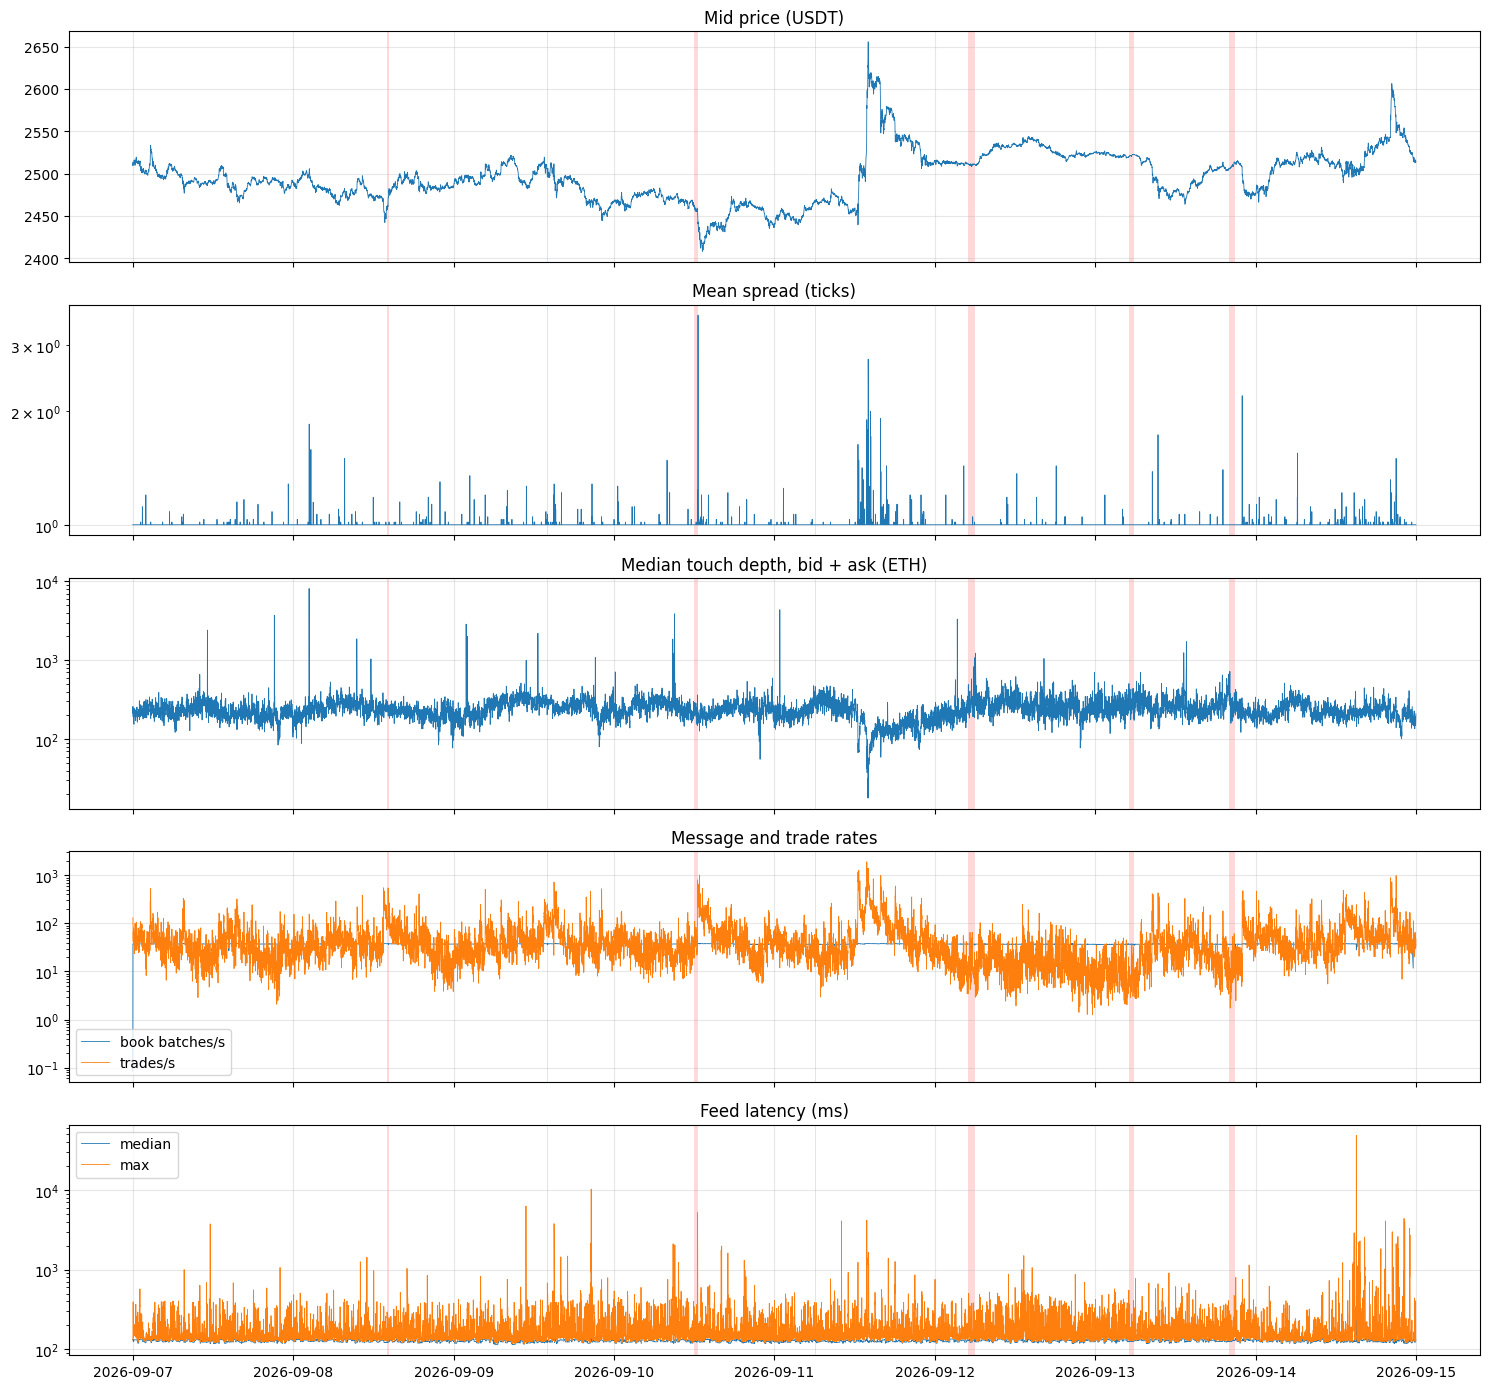

In [10]:
ps = persec.copy(); ps['m'] = ps.sec // 60
pm = ps.groupby('m').agg(mid=('mid', 'last'), spread=('spread', 'mean'), depth=('depth', 'median'),
                         batches=('batches', 'sum'), lat_med=('lat', 'median'), lat_max=('lat', 'max'), valid=('valid', 'min'))
pm = pm.join(tmin.groupby('m').sum(), how='left')
x = pd.to_datetime(pm.index * 60, unit='s')
fig, ax = plt.subplots(5, 1, figsize=(15, 14), sharex=True)
ax[0].plot(x, pm.mid, lw=.6); ax[0].set_title('Mid price (USDT)')
ax[1].plot(x, pm.spread, lw=.6); ax[1].set_title('Mean spread (ticks)'); ax[1].set_yscale('log')
ax[2].plot(x, pm.depth, lw=.6); ax[2].set_title('Median touch depth, bid + ask (ETH)'); ax[2].set_yscale('log')
ax[3].plot(x, pm.batches / 60, lw=.6, label='book batches/s'); ax[3].plot(x, pm.trades / 60, lw=.6, label='trades/s'); ax[3].legend(); ax[3].set_yscale('log'); ax[3].set_title('Message and trade rates')
ax[4].plot(x, pm.lat_med, lw=.6, label='median'); ax[4].plot(x, pm.lat_max, lw=.6, label='max'); ax[4].set_yscale('log'); ax[4].legend(); ax[4].set_title('Feed latency (ms)')
bad = x[pm.valid.fillna(1).to_numpy() == 0]
for a in ax:
    a.grid(alpha=.3)
    for t in bad: a.axvspan(t, t + pd.Timedelta(minutes=1), color='red', alpha=.15, lw=0)
plt.tight_layout(); fig.savefig(REP / '02_overview.png', dpi=110); plt.show()

## 7 · Daily integrity report and the final Stage 0 gate

In [11]:
# --- book side (from notebook 01)
brk_files = sync.groupby('file').filter(lambda f: f.chain_breaks.sum() > 0)
resynced = brk_files.groupby('file').apply(lambda f: bool(((f.segment > f.loc[f.chain_breaks > 0, 'segment'].max()) &
                                             f['mode'].isin(['snapshot_linked', 'snapshot_bracket']) & (f.chain_breaks == 0)).any()),
                                             include_groups=False)
report = pd.DataFrame({
    'trades': integ.set_index('date').rows, 'joined_share': day.trades / integ.set_index('date').rows,
    'missing_id_share': integ.set_index('date').missing_id_share,
    'usable_share': tab.usable_share.drop('ALL'), 'unexplained': tab.unexplained.drop('ALL'),
    'unexplained_vol': tab.unexplained_vol.drop('ALL'), 'sweep_preceded': sweep.deeper_preceded,
    'sweep_monotone': sweep.monotone_batch_sides,
    'invalid_batches': sync.groupby('date').invalid_batches.sum(), 'chain_breaks': sync.groupby('date').chain_breaks.sum(),
    'lat_p99_worst_ms': sync.groupby('date').lat_p99_ms.max()})
display(report.style.format({'trades': '{:,.0f}', 'joined_share': '{:.3%}', 'missing_id_share': '{:.3%}', 'usable_share': '{:.2%}', 'unexplained': '{:.3%}',
                             'unexplained_vol': '{:.3%}', 'sweep_preceded': '{:.2%}', 'sweep_monotone': '{:.2%}',
                             'invalid_batches': '{:,.0f}', 'chain_breaks': '{:,.0f}', 'lat_p99_worst_ms': '{:,.0f}'}))
report.to_csv(REP / '02_daily_integrity.csv')
gate = {
    'BOOK  all 192 hours reconstructed': sync[['date', 'hour']].drop_duplicates().shape[0] == 24 * len(DATES),
    'BOOK  C++ == numba on every batch of every hour': bool(len(xchk) == 24 * len(DATES) and xchk.equal.all()),
    'BOOK  zero crossed books in valid batches': int(sync.loc[sync.invalid_batches == 0, 'crossed_batches'].sum()) == 0,
    'BOOK  every pu break followed by a resync snapshot in the same hour': bool(resynced.all()) if len(resynced) else True,
    'BOOK  exact snapshot audits wherever replay and snapshot share an update id':
        bool(sync.loc[sync.L_minus_prev_last_u == 0, 'audit_exact'].map({True: True, False: False, 'True': True, 'False': False}).all()),
    'TRADES all days loaded, no duplicate/backward IDs, time never decreases':
        len(integ) == len(DATES) and int(integ.dup_or_backward_ids.sum()) == 0 and int(integ.time_decreases.sum()) == 0,
    'TRADES on grid and quote_qty == price × qty exactly': int(integ[['offgrid_px', 'offgrid_qty', 'quote_mismatch', 'bad_side_values']].sum().sum()) == 0,
    f'JOIN  unexplained ≤ {MAX_UNEXPLAINED_TRADES:.1%} of usable trades, every day': bool((report.unexplained <= MAX_UNEXPLAINED_TRADES).all()),
    f'JOIN  unexplained ≤ {MAX_UNEXPLAINED_VOLUME:.1%} of usable volume, every day': bool((report.unexplained_vol <= MAX_UNEXPLAINED_VOLUME).all()),
    f'JOIN  sweep fills preceded by a touch fill ≥ {MIN_SWEEP_PRECEDED:.0%}, every day': bool((report.sweep_preceded >= MIN_SWEEP_PRECEDED).all()),
    f'JOIN  sweeps walk the book in order ≥ {MIN_SWEEP_MONOTONE:.0%}, every day': bool((report.sweep_monotone >= MIN_SWEEP_MONOTONE).all()),
    f'JOIN  ≥ {MIN_USABLE_SHARE:.0%} of trades in valid book periods, every day': bool((report.usable_share >= MIN_USABLE_SHARE).all()),
    'JOIN  ≥ 99.9% of each day\'s trades matched to a book batch': bool((report.joined_share >= 0.999).all()),
}
for k, v in gate.items(): print(('PASS  ' if v else 'FAIL  ') + k)
print('\nSTAGE 0:', 'PASSED' if all(gate.values()) else 'NOT PASSED: see FAIL lines')

,trades,joined_share,missing_id_share,usable_share,unexplained,unexplained_vol,sweep_preceded,sweep_monotone,invalid_batches,chain_breaks,lat_p99_worst_ms
date,,,,,,,,,,,
2026-09-07,"3,599,862",100.000%,0.489%,99.74%,0.571%,1.697%,96.18%,98.93%,654,58,160
2026-09-08,"4,254,574",100.000%,0.425%,96.91%,0.570%,1.564%,96.18%,98.82%,"31,797",20,224
2026-09-09,"4,687,541",100.000%,0.397%,99.01%,0.600%,1.858%,96.08%,98.84%,"9,259",11,950
2026-09-10,"4,552,897",100.000%,0.397%,97.00%,0.645%,1.997%,95.89%,98.65%,"69,036",20,353
2026-09-11,"7,910,411",100.000%,0.302%,99.80%,1.960%,4.215%,95.28%,96.29%,"20,041",20,495
2026-09-12,"1,713,727",100.000%,0.586%,96.65%,0.486%,1.432%,96.32%,99.16%,"132,167",82,307
2026-09-13,"2,734,970",100.000%,0.372%,97.10%,0.714%,1.927%,95.60%,98.84%,"236,492",58,175
2026-09-14,"5,801,859",99.996%,0.386%,98.30%,0.788%,2.559%,95.47%,98.31%,"15,147",144,"30,745"


PASS  BOOK  all 192 hours reconstructed
PASS  BOOK  C++ == numba on every batch of every hour
PASS  BOOK  zero crossed books in valid batches
PASS  BOOK  every pu break followed by a resync snapshot in the same hour
PASS  BOOK  exact snapshot audits wherever replay and snapshot share an update id
PASS  TRADES all days loaded, no duplicate/backward IDs, time never decreases
PASS  TRADES on grid and quote_qty == price × qty exactly
FAIL  JOIN  unexplained ≤ 0.5% of usable trades, every day
FAIL  JOIN  unexplained ≤ 1.0% of usable volume, every day
PASS  JOIN  sweep fills preceded by a touch fill ≥ 95%, every day
FAIL  JOIN  sweeps walk the book in order ≥ 99%, every day
PASS  JOIN  ≥ 95% of trades in valid book periods, every day
PASS  JOIN  ≥ 99.9% of each day's trades matched to a book batch

STAGE 0: NOT PASSED: see FAIL lines


In [12]:
G = hourly.sum(numeric_only=True)
lines = ['# 02 · Trades and trade–book tests: summary', '',
         f"trades: {int(integ.rows.sum()):,} over {len(integ)} days; missing IDs {int(integ.missing_ids.sum()):,} ({integ.missing_ids.sum()/(integ.last_id - integ.first_id + 1).sum():.3%})",
         f"matched to a book batch: {G.trades/integ.rows.sum():.3%}; usable (valid book): {G.usable/G.trades:.2%}",
         f"at touch {G.n_at_touch/G.usable:.2%} | deeper top-10 {G.n_deeper_top10/G.usable:.2%} | beyond top-10 {G.n_beyond_top10/G.usable:.2%} | "
         f"1-batch slack {G.n_one_batch_slack/G.usable:.2%}",
         f"UNEXPLAINED {(G.n_inside_spread + G.n_wrong_side + G.n_other)/G.usable:.3%} of trades, "
         f"{(G.v_inside_spread + G.v_wrong_side + G.v_other)/G.vol_usable:.3%} of volume",
         f"sweeps preceded {G.deeper_preceded/G.deeper_total:.2%} (beyond top-10: {G.beyond_preceded/G.beyond_total:.2%}); monotone {G.mono_groups/G.groups:.2%}",
         f"test 3: V <= q_pre {G.touch_v_le_qpre/G.touch_groups:.2%}; refill within batch {G.touch_refill_needed/G.touch_groups:.2%}",
         f"missing-ID test: depletion ratio gap/other {(G.dep_gap_sum/G.quiet_gap)/(G.dep_other_sum/G.quiet_other):.3f}, "
         f"P(dep) {G.dep_gap_pos/G.quiet_gap:.3f} vs {G.dep_other_pos/G.quiet_other:.3f}",
         f"quality windows: {windows.groupby('reason').minutes.sum().round(1).to_dict() if len(windows) else {}}", '']
lines += [('PASS ' if v else 'FAIL ') + k for k, v in gate.items()]
lines += ['', 'STAGE 0: ' + ('PASSED' if all(gate.values()) else 'NOT PASSED')]
(REP / '02_summary.md').write_text('\n'.join(lines), encoding='utf-8'); print('\n'.join(lines))
print('\nSend me: reports/02_summary.md, 02_daily_integrity.csv, 02_join_by_day.csv, 02_trades_integrity.csv, 02_quality_windows.csv, 02_overview.png')

# 02 · Trades and trade–book tests: summary

trades: 35,255,841 over 8 days; missing IDs 139,453 (0.394%)
matched to a book batch: 99.999%; usable (valid book): 98.37%
at touch 43.01% | deeper top-10 27.08% | beyond top-10 27.96% | 1-batch slack 1.00%
UNEXPLAINED 0.943% of trades, 2.475% of volume
sweeps preceded 95.76% (beyond top-10: 94.48%); monotone 98.25%
test 3: V <= q_pre 97.63%; refill within batch 31.43%
missing-ID test: depletion ratio gap/other 1.042, P(dep) 0.267 vs 0.258
quality windows: {'invalid_book': 231.0, 'latency': 4.8, 'resync_gap': 13.4}

PASS BOOK  all 192 hours reconstructed
PASS BOOK  C++ == numba on every batch of every hour
PASS BOOK  zero crossed books in valid batches
PASS BOOK  every pu break followed by a resync snapshot in the same hour
PASS BOOK  exact snapshot audits wherever replay and snapshot share an update id
PASS TRADES all days loaded, no duplicate/backward IDs, time never decreases
PASS TRADES on grid and quote_qty == price × qty exactly
FAIL J